# Modelling and Tracking Shared E-Scooters under Correlated Noise in Urban Environments

## Part I. Effects of Ignoring Correlated State and Measurement Noise in Kalman Filtering
### Background and useful recommendations

In [57]:
import numpy as np
from matplotlib import pyplot as plt

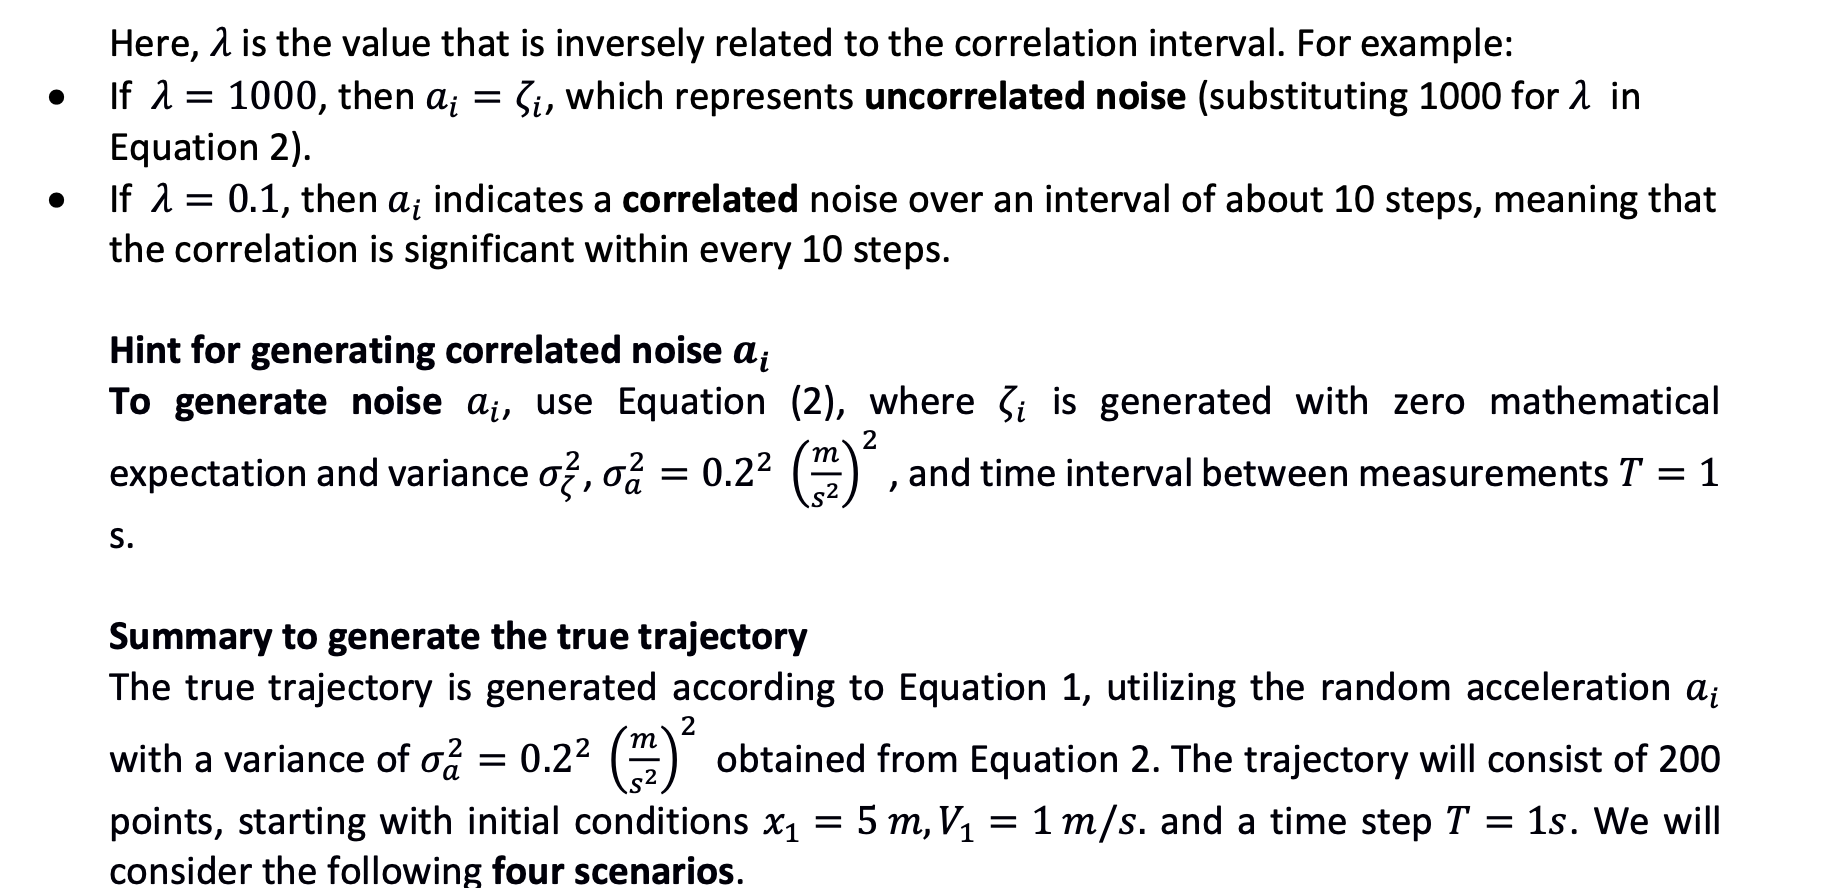

In [58]:
# defining the constants

VARIANCE_A = 0.2**2  
VARIANCE_ETA = 20**2

POINTS = 200
M = 500

T = 1
X_INIT = 5
V_INIT = 1

LAMBDA_CORRELATED = 0.1
LAMBDA_UNCORRELATED = 1000

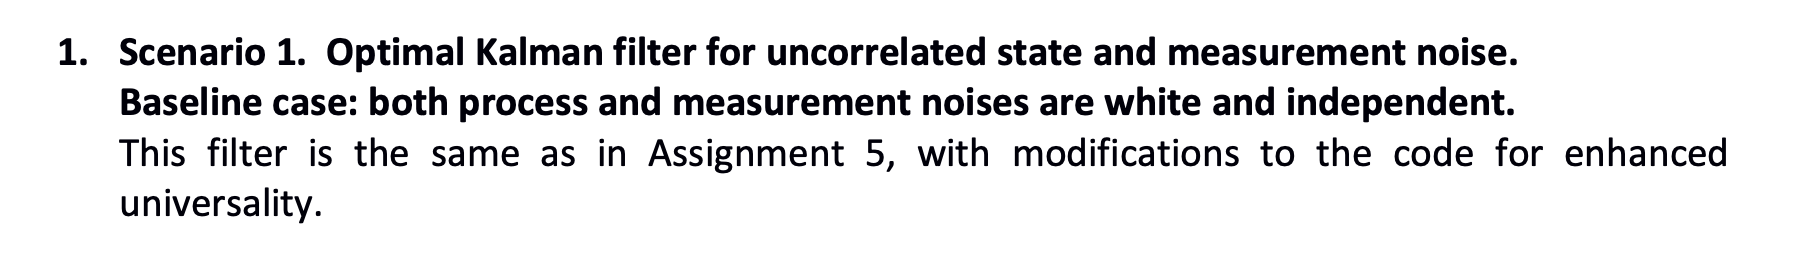

In [59]:
# state-space model for the scooter's motion

# transition matrix Phi
PHI = np.array([[1, T],
                [0, 1]])

# input matrix G that defines how the random acceleration a_i influences the state vector
G = np.array([[T**2 / 2],
              [T]])

# observation matrix H that relates the measurement vector to the state vector 
H = np.array([[1, 0]])

# covariance matrix Q of the state noise G * a_i
Q = G @ G.T * VARIANCE_A

print(Q)

# covariance matrix R of the measurement noise
R = np.array([[VARIANCE_ETA]])

print(R)

[[0.01 0.02]
 [0.02 0.04]]
[[400]]


In [60]:
# setting the initial conditions for the filtered estimate and the filtration error covariance matrix

# initial filtered estimate of the state vector 
X_0_0 = np.array([[X_INIT],
                  [V_INIT]])

# initial filtration error covariance matrix,
# identical to the more accurate matrix from assignment 6
P_0_0 = np.array([[100, 0],
                  [0, 100]])

In [61]:
# Kalman filter as a function
def kalman_filter(measurements, phi, h, q, r, x_0_0, p_0_0):
    size = measurements.size

    x_pred = np.zeros((size, 2, 1))   # predicted state X_{i,i-1}
    p_pred = np.zeros((size, 2, 2))   # prediction error covariance P_{i,i-1}
    x_filt = np.zeros((size, 2, 1))   # filtered state X_{i,i}
    p_filt = np.zeros((size, 2, 2))   # filtration error covariance P_{i,i}
    k = np.zeros((size, 2, 1))        # filter gain K_i

    identity = np.eye(2)
    x_prev = x_0_0
    p_prev = p_0_0

    x_pred[0] = x_prev
    p_pred[0] = p_prev
    x_filt[0] = x_pred[0]
    p_filt[0] = p_pred[0]

    for i in range(1, size):
        # prediction
        x_pred[i] = phi @ x_prev
        p_pred[i] = phi @ p_prev @ phi.T + q

        # filtration
        k[i] = p_pred[i] @ h.T @ np.linalg.inv(h @ p_pred[i] @ h.T + r)
        x_filt[i] = x_pred[i] + k[i] * (measurements[i] - h @ x_pred[i])
        p_filt[i] = (identity - k[i] @ h) @ p_pred[i]

        x_prev = x_filt[i]
        p_prev = p_filt[i]

    return x_pred, p_pred, x_filt, p_filt, k

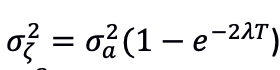

In [62]:
# find uncorrelated noise zeta
def get_zeta(lam, variance_a=VARIANCE_A, t=T):
    variance_zeta = variance_a * (1 - np.exp(-2 * lam * t))
    return np.random.normal(loc=0.0, scale=np.sqrt(variance_zeta))

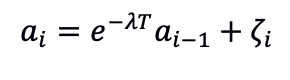
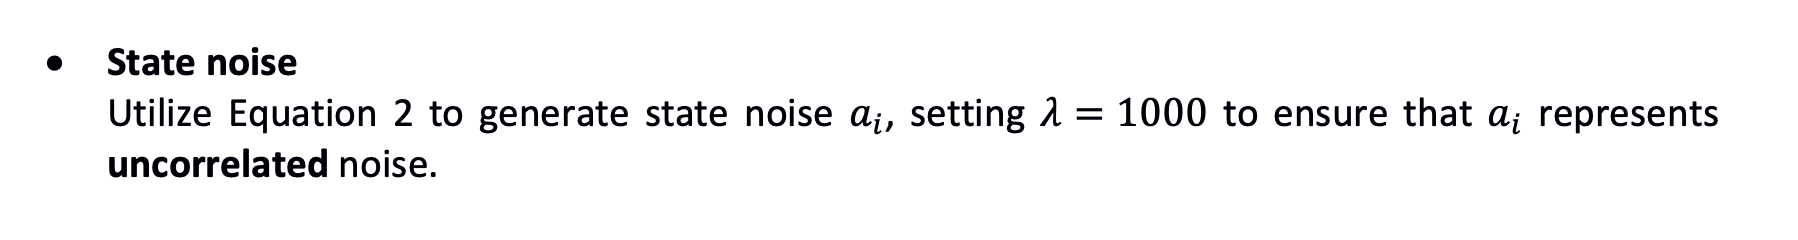

In [63]:
# a function to generate a true trajectory of an e-scooter 
def generate_true_trajectory(lam, size=POINTS, init_coord=X_INIT, init_velocity=V_INIT, sigma_a=np.sqrt(VARIANCE_A), t=T):
    traj_points = np.zeros(size)
    velocity_points = np.zeros(size)
    traj_points[0] = init_coord
    velocity_points[0] = init_velocity
    acceleration = np.random.normal(loc=0.0, scale=sigma_a)

    for i in range(1, size):
        traj_points[i] = traj_points[i-1] + velocity_points[i-1] * t + acceleration * t**2 / 2
        velocity_points[i] = velocity_points[i-1] + acceleration * t
        zeta = get_zeta(lam)
        acceleration = np.exp(-lam * t) * acceleration + zeta

    return traj_points, velocity_points

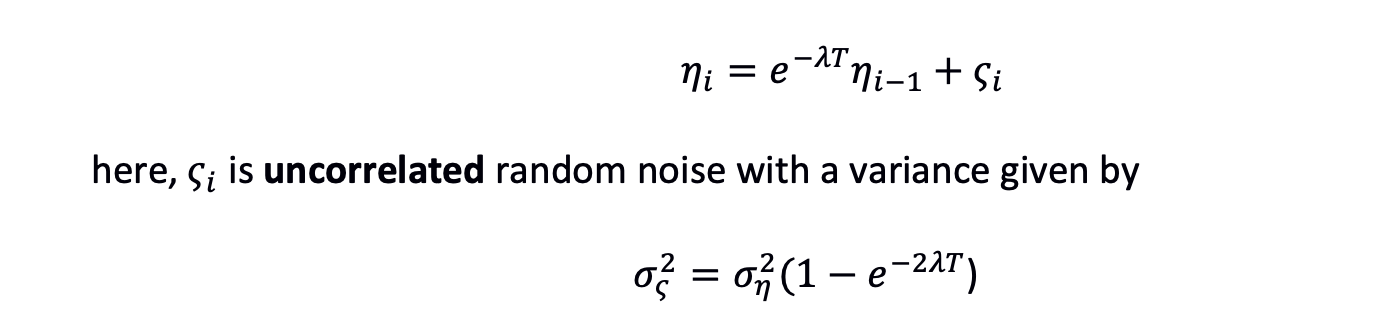

In [66]:
# find uncorrelated noise final sigma
def get_final_sigma(lam, variance_eta=VARIANCE_ETA, t=T):
    variance_fsigma = variance_eta * (1 - np.exp(-2 * lam * t))
    return np.random.normal(loc=0.0, scale=np.sqrt(variance_fsigma))

# a function to generate measurements of the coordinate
def generate_measurements(true_trajectory, lam, t=T, sigma_eta=np.sqrt(VARIANCE_ETA)):
    measurements = np.zeros(len(true_trajectory))
    eta = np.random.normal(loc=0.0, scale=sigma_eta)

    for i in range(len(true_trajectory)):
        eta = np.exp(-lam * t) * eta + get_final_sigma(lam)
        measurements[i] = true_trajectory[i] + eta
    return measurements

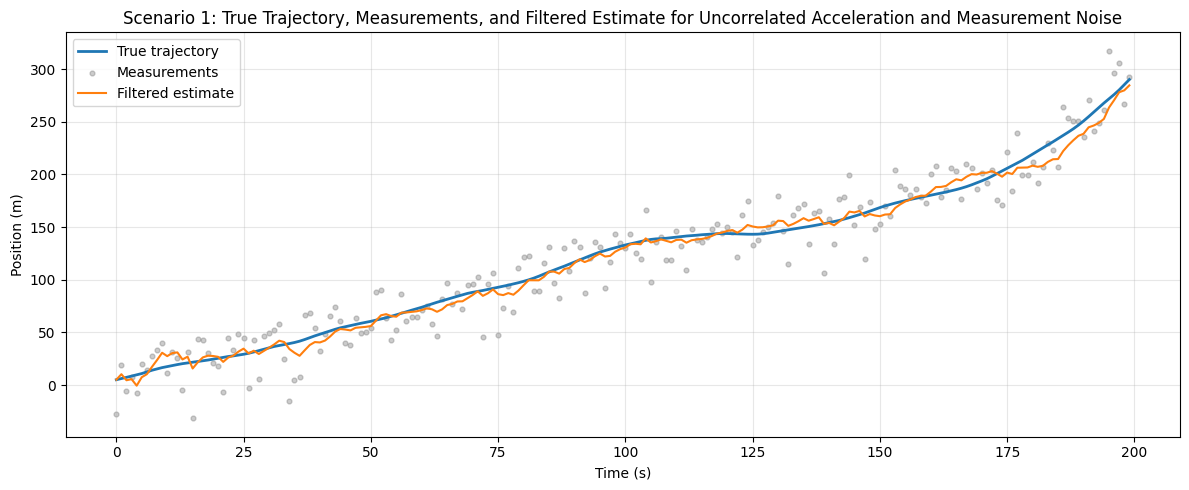

In [72]:
# scenario 1: uncorrelated state and measurement noise
true_trajectory, true_velocity = generate_true_trajectory(
    lam=LAMBDA_UNCORRELATED
)

measurements = generate_measurements(
    true_trajectory,
    lam=LAMBDA_UNCORRELATED
)

x_pred, p_pred, x_filt, p_filt, k = kalman_filter(
    measurements, PHI, H, Q, R, X_0_0, P_0_0
)

time = np.arange(POINTS) * T

plt.figure(figsize=(12, 5))
plt.plot(time, true_trajectory, label="True trajectory", linewidth=2)
plt.scatter(
    time, measurements,
    label="Measurements", s=12, alpha=0.4, color="gray"
)
plt.plot(time, x_filt[:, 0, 0], label="Filtered estimate")

plt.xlabel("Time (s)")
plt.ylabel("Position (m)")
plt.title("Scenario 1: True Trajectory, Measurements, and Filtered Estimate for Uncorrelated Acceleration and Measurement Noise")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

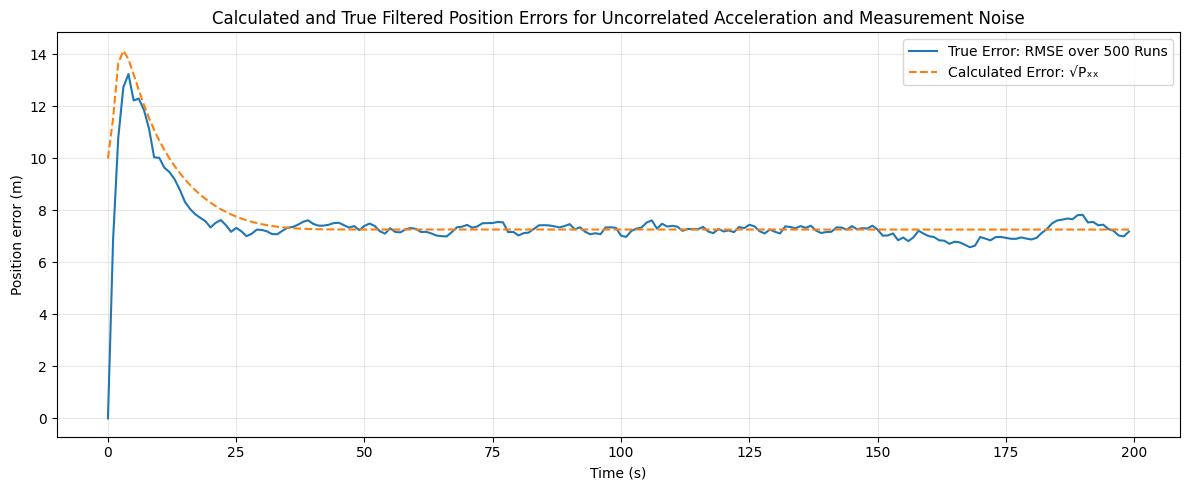

In [71]:
position_errors = np.zeros((M, POINTS))

for m in range(M):
    true_trajectory, _ = generate_true_trajectory(
        lam=LAMBDA_UNCORRELATED
    )

    measurements = generate_measurements(
        true_trajectory,
        lam=LAMBDA_UNCORRELATED
    )

    _, _, x_filt, p_filt, _ = kalman_filter(
        measurements, PHI, H, Q, R, X_0_0, P_0_0
    )

    position_errors[m] = x_filt[:, 0, 0] - true_trajectory

true_rmse = np.sqrt(np.mean(position_errors**2, axis=0))
calculated_sigma = np.sqrt(p_filt[:, 0, 0])

plt.figure(figsize=(12, 5))
plt.plot(time, true_rmse, label=f"True Error: RMSE over {M} Runs")
plt.plot(
    time, calculated_sigma,
    linestyle="--", label="Calculated Error: √Pₓₓ"
)

plt.xlabel("Time (s)")
plt.ylabel("Position error (m)")
plt.title("Calculated and True Filtered Position Errors for Uncorrelated Acceleration and Measurement Noise")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

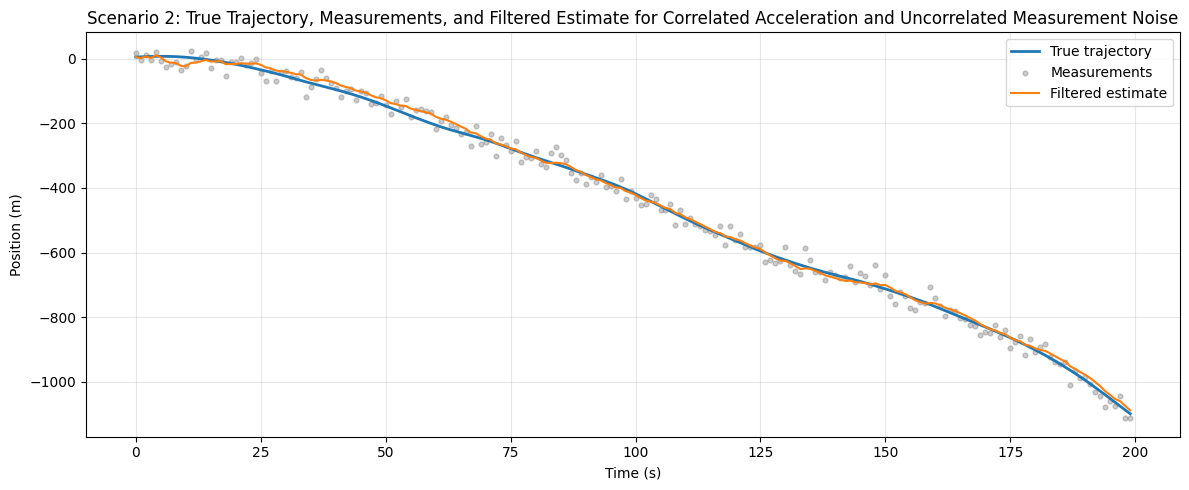

In [75]:
# scenario 2: correlated acceleration, uncorrelated measurements
true_trajectory_2, _ = generate_true_trajectory(
    lam=LAMBDA_CORRELATED
)

measurements_2 = generate_measurements(
    true_trajectory_2,
    lam=LAMBDA_UNCORRELATED
)

_, _, x_filt_2, _, _ = kalman_filter(
    measurements_2, PHI, H, Q, R, X_0_0, P_0_0
)

time = np.arange(POINTS) * T

plt.figure(figsize=(12, 5))
plt.plot(time, true_trajectory_2, label="True trajectory", linewidth=2)
plt.scatter(
    time, measurements_2,
    label="Measurements", s=12, alpha=0.4, color="gray"
)
plt.plot(time, x_filt_2[:, 0, 0], label="Filtered estimate")

plt.xlabel("Time (s)")
plt.ylabel("Position (m)")
plt.title("Scenario 2: True Trajectory, Measurements, and Filtered Estimate for Correlated Acceleration and Uncorrelated Measurement Noise")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

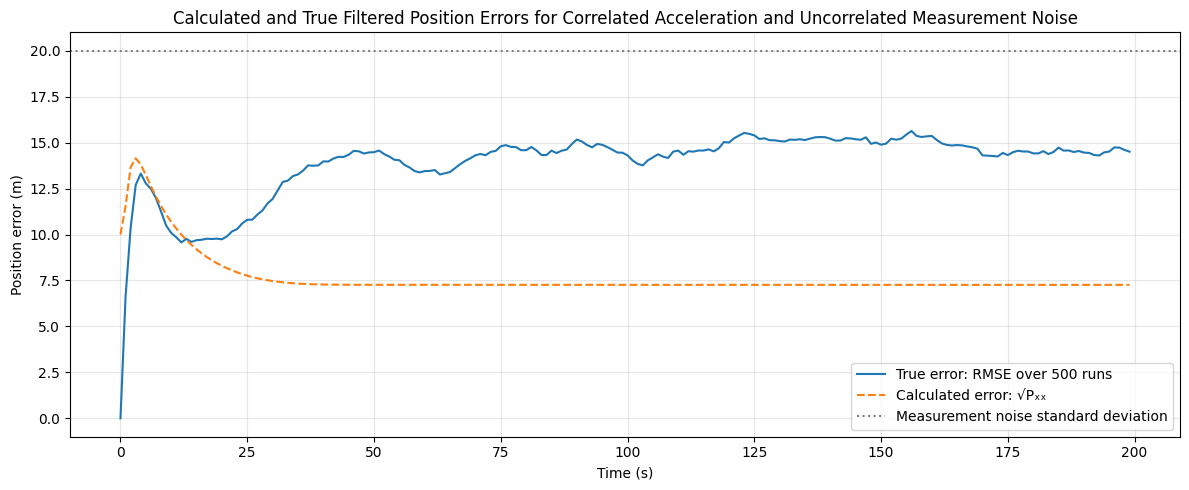

In [77]:
position_errors_2 = np.zeros((M, POINTS))

for m in range(M):
    true_trajectory_2, _ = generate_true_trajectory(
        lam=LAMBDA_CORRELATED
    )

    measurements_2 = generate_measurements(
        true_trajectory_2,
        lam=LAMBDA_UNCORRELATED
    )

    _, _, x_filt_2, p_filt_2, _ = kalman_filter(
        measurements_2, PHI, H, Q, R, X_0_0, P_0_0
    )

    position_errors_2[m] = (
        x_filt_2[:, 0, 0] - true_trajectory_2
    )

true_rmse_2 = np.sqrt(np.mean(position_errors_2**2, axis=0))
calculated_sigma_2 = np.sqrt(p_filt_2[:, 0, 0])

plt.figure(figsize=(12, 5))
plt.plot(time, true_rmse_2, label=f"True error: RMSE over {M} runs")
plt.plot(
    time, calculated_sigma_2,
    linestyle="--", label="Calculated error: √Pₓₓ"
)
plt.axhline(
    np.sqrt(VARIANCE_ETA),
    color="gray", linestyle=":",
    label="Measurement noise standard deviation"
)

plt.xlabel("Time (s)")
plt.ylabel("Position error (m)")
plt.title("Calculated and True Filtered Position Errors for Correlated Acceleration and Uncorrelated Measurement Noise")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

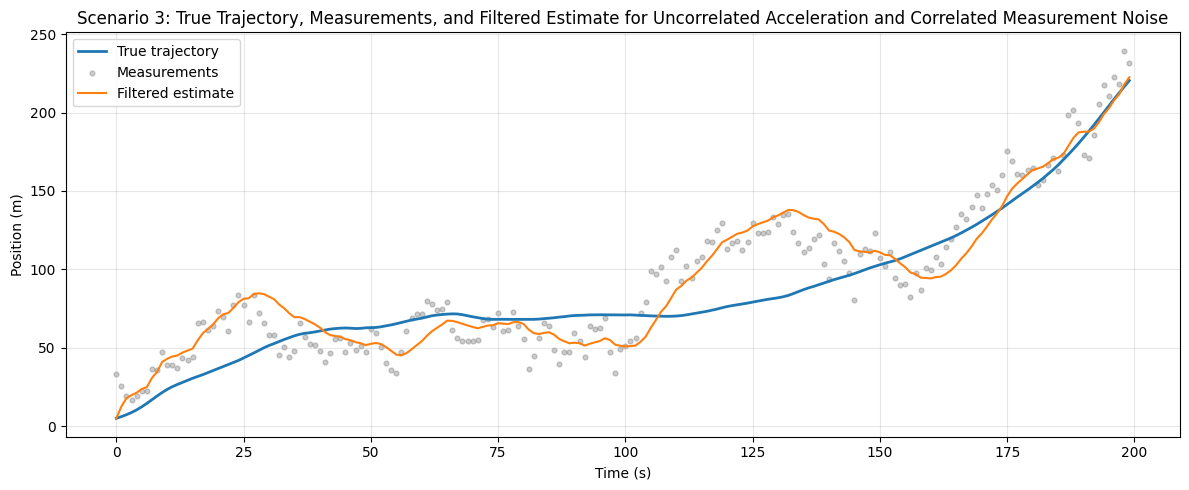

In [90]:
# scenario 3: uncorrelated acceleration, correlated measurements
true_trajectory_3, _ = generate_true_trajectory(
    lam=LAMBDA_UNCORRELATED
)

measurements_3 = generate_measurements(
    true_trajectory_3,
    lam=LAMBDA_CORRELATED
)

_, _, x_filt_3, _, _ = kalman_filter(
    measurements_3, PHI, H, Q, R, X_0_0, P_0_0
)

time = np.arange(POINTS) * T

plt.figure(figsize=(12, 5))
plt.plot(time, true_trajectory_3, label="True trajectory", linewidth=2)
plt.scatter(
    time, measurements_3,
    label="Measurements", s=12, alpha=0.4, color="gray"
)
plt.plot(time, x_filt_3[:, 0, 0], label="Filtered estimate")

plt.xlabel("Time (s)")
plt.ylabel("Position (m)")
plt.title("Scenario 3: True Trajectory, Measurements, and Filtered Estimate for Uncorrelated Acceleration and Correlated Measurement Noise")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

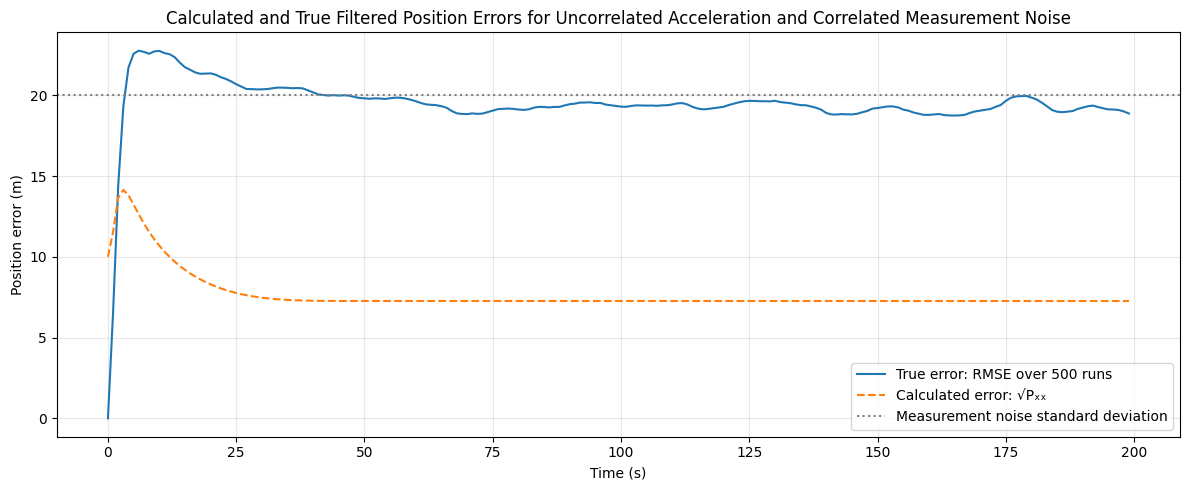

In [93]:
position_errors_3 = np.zeros((M, POINTS))

for m in range(M):
    true_trajectory_3, _ = generate_true_trajectory(
        lam=LAMBDA_UNCORRELATED
    )

    measurements_3 = generate_measurements(
        true_trajectory_3,
        lam=LAMBDA_CORRELATED
    )

    _, _, x_filt_3, p_filt_3, _ = kalman_filter(
        measurements_3, PHI, H, Q, R, X_0_0, P_0_0
    )

    position_errors_3[m] = (
        x_filt_3[:, 0, 0] - true_trajectory_3
    )

true_rmse_3 = np.sqrt(np.mean(position_errors_3**2, axis=0))
calculated_sigma_3 = np.sqrt(p_filt_3[:, 0, 0])

plt.figure(figsize=(12, 5))
plt.plot(time, true_rmse_3, label=f"True error: RMSE over {M} runs")
plt.plot(
    time, calculated_sigma_3,
    linestyle="--", label="Calculated error: √Pₓₓ"
)
plt.axhline(
    np.sqrt(VARIANCE_ETA),
    color="gray", linestyle=":",
    label="Measurement noise standard deviation"
)

plt.xlabel("Time (s)")
plt.ylabel("Position error (m)")
plt.title("Calculated and True Filtered Position Errors for Uncorrelated Acceleration and Correlated Measurement Noise")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

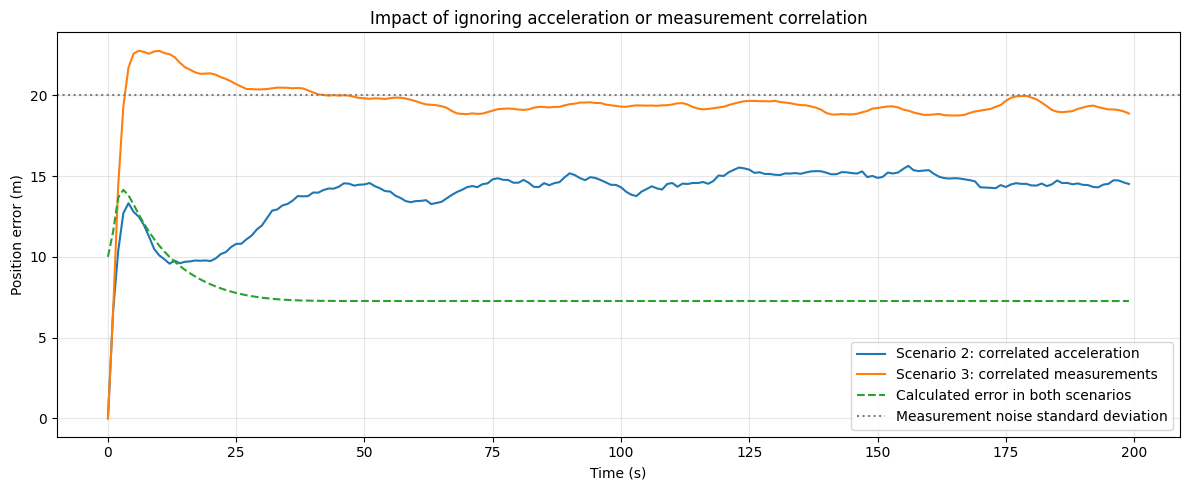

In [94]:
plt.figure(figsize=(12, 5))
plt.plot(time, true_rmse_2, label="Scenario 2: correlated acceleration")
plt.plot(time, true_rmse_3, label="Scenario 3: correlated measurements")
plt.plot(
    time, calculated_sigma_3,
    linestyle="--", label="Calculated error in both scenarios"
)
plt.axhline(
    np.sqrt(VARIANCE_ETA),
    color="gray", linestyle=":",
    label="Measurement noise standard deviation"
)

plt.xlabel("Time (s)")
plt.ylabel("Position error (m)")
plt.title("Impact of ignoring acceleration or measurement correlation")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

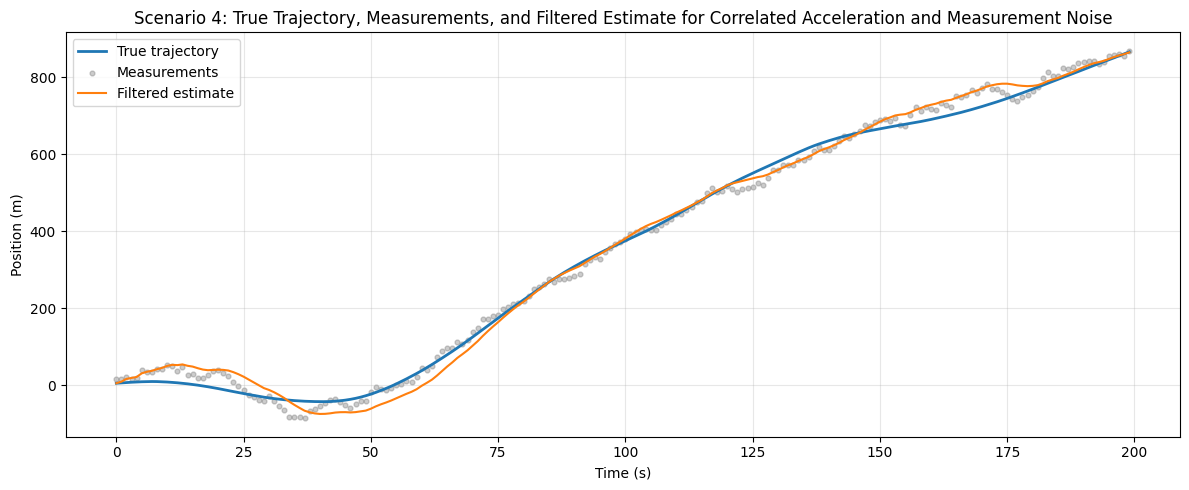

In [98]:
# Scenario 4: correlated acceleration and measurement noise
true_trajectory_4, _ = generate_true_trajectory(
    lam=LAMBDA_CORRELATED
)

measurements_4 = generate_measurements(
    true_trajectory_4,
    lam=LAMBDA_CORRELATED
)

_, _, x_filt_4, _, _ = kalman_filter(
    measurements_4, PHI, H, Q, R, X_0_0, P_0_0
)

time = np.arange(POINTS) * T

plt.figure(figsize=(12, 5))
plt.plot(time, true_trajectory_4, label="True trajectory", linewidth=2)
plt.scatter(
    time, measurements_4,
    label="Measurements", s=12, alpha=0.4, color="gray"
)
plt.plot(time, x_filt_4[:, 0, 0], label="Filtered estimate")

plt.xlabel("Time (s)")
plt.ylabel("Position (m)")
plt.title("Scenario 4: True Trajectory, Measurements, and Filtered Estimate for Correlated Acceleration and Measurement Noise")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

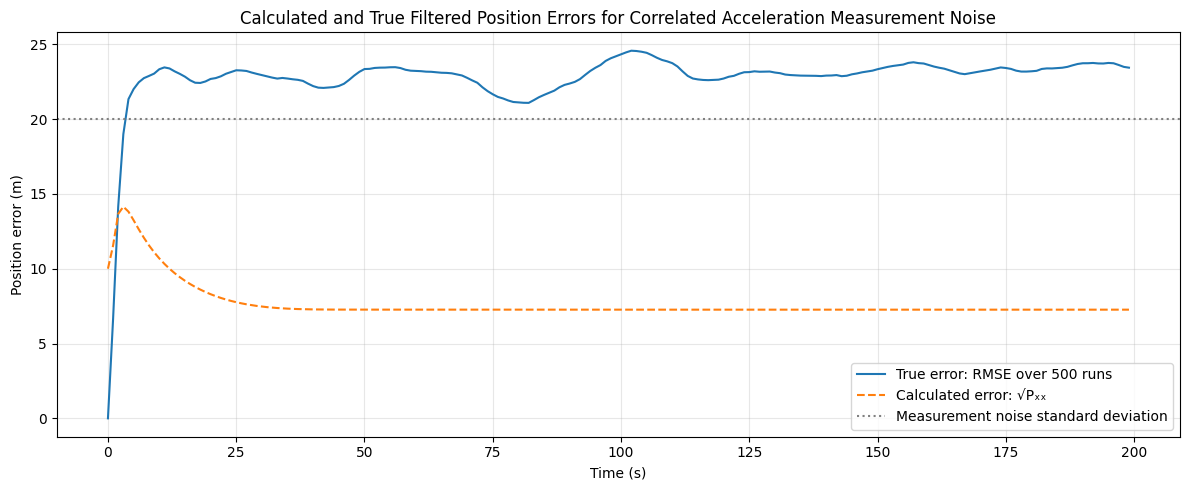

In [99]:
position_errors_4 = np.zeros((M, POINTS))

for m in range(M):
    true_trajectory_4, _ = generate_true_trajectory(
        lam=LAMBDA_CORRELATED
    )

    measurements_4 = generate_measurements(
        true_trajectory_4,
        lam=LAMBDA_CORRELATED
    )

    _, _, x_filt_4, p_filt_4, _ = kalman_filter(
        measurements_4, PHI, H, Q, R, X_0_0, P_0_0
    )

    position_errors_4[m] = (
        x_filt_4[:, 0, 0] - true_trajectory_4
    )

true_rmse_4 = np.sqrt(np.mean(position_errors_4**2, axis=0))
calculated_sigma_4 = np.sqrt(p_filt_4[:, 0, 0])

plt.figure(figsize=(12, 5))
plt.plot(time, true_rmse_4, label=f"True error: RMSE over {M} runs")
plt.plot(
    time, calculated_sigma_4,
    linestyle="--", label="Calculated error: √Pₓₓ"
)
plt.axhline(
    np.sqrt(VARIANCE_ETA),
    color="gray", linestyle=":",
    label="Measurement noise standard deviation"
)

plt.xlabel("Time (s)")
plt.ylabel("Position error (m)")
plt.title("Calculated and True Filtered Position Errors for Correlated Acceleration Measurement Noise")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

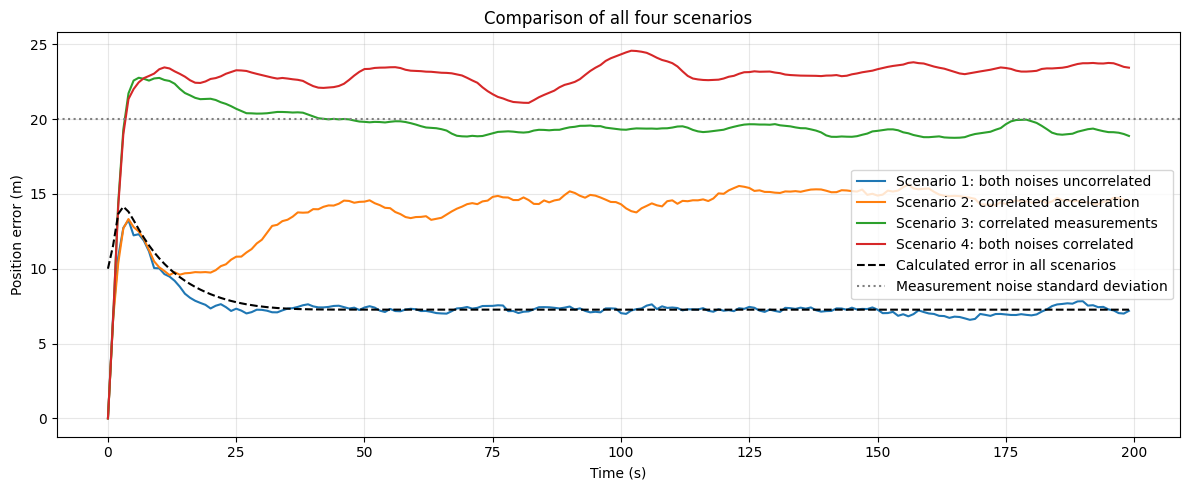

In [100]:
plt.figure(figsize=(12, 5))
plt.plot(time, true_rmse, label="Scenario 1: both noises uncorrelated")
plt.plot(time, true_rmse_2, label="Scenario 2: correlated acceleration")
plt.plot(time, true_rmse_3, label="Scenario 3: correlated measurements")
plt.plot(time, true_rmse_4, label="Scenario 4: both noises correlated")
plt.plot(
    time, calculated_sigma_4,
    color="black", linestyle="--",
    label="Calculated error in all scenarios"
)
plt.axhline(
    np.sqrt(VARIANCE_ETA),
    color="gray", linestyle=":",
    label="Measurement noise standard deviation"
)

plt.xlabel("Time (s)")
plt.ylabel("Position error (m)")
plt.title("Comparison of all four scenarios")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()